In [13]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
import matplotlib.pyplot as plt

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


In [14]:
import os

dataset_path = r"C:\Users\dell\OneDrive\Desktop\Seed_Project\Seed_type4.2"

for root, dirs, files in os.walk(dataset_path):
    print(root)
    print("Folders:", dirs)
    print("Files:", len(files))
    print("-"*50)


C:\Users\dell\OneDrive\Desktop\Seed_Project\Seed_type4.2
Folders: ['Amla Seed', 'Apple Seed', 'Avocado Seed', 'Betel Nut Seed', 'Black Plum Seed', 'Corn Seed', 'Date Seed', 'Flax Seed', 'Hog Plum Seed', 'Jackfruit Seed', 'Litchi Seed', 'Mango Seed', 'Mustard Seed', 'Olive Seed', 'Orange Seed', 'Paddy Seed', 'Pumpkin Seed', 'Safflower Seed', 'Sapodilla Seed', 'Sesame Seed', 'Soybean Seed', 'Sunflower Seed', 'Tamarind Seed', 'Wheat Seed']
Files: 0
--------------------------------------------------
C:\Users\dell\OneDrive\Desktop\Seed_Project\Seed_type4.2\Amla Seed
Folders: []
Files: 360
--------------------------------------------------
C:\Users\dell\OneDrive\Desktop\Seed_Project\Seed_type4.2\Apple Seed
Folders: []
Files: 360
--------------------------------------------------
C:\Users\dell\OneDrive\Desktop\Seed_Project\Seed_type4.2\Avocado Seed
Folders: []
Files: 180
--------------------------------------------------
C:\Users\dell\OneDrive\Desktop\Seed_Project\Seed_type4.2\Betel Nut Seed


In [15]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

dataset_path = r"C:\Users\dell\OneDrive\Desktop\Seed_Project\Seed_type4.2"

datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_generator = datagen.flow_from_directory(
    dataset_path,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    subset='training'
)

val_generator = datagen.flow_from_directory(
    dataset_path,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    subset='validation'
)

print("Classes:", train_generator.class_indices)


Found 16715 images belonging to 24 classes.
Found 4174 images belonging to 24 classes.
Classes: {'Amla Seed': 0, 'Apple Seed': 1, 'Avocado Seed': 2, 'Betel Nut Seed': 3, 'Black Plum Seed': 4, 'Corn Seed': 5, 'Date Seed': 6, 'Flax Seed': 7, 'Hog Plum Seed': 8, 'Jackfruit Seed': 9, 'Litchi Seed': 10, 'Mango Seed': 11, 'Mustard Seed': 12, 'Olive Seed': 13, 'Orange Seed': 14, 'Paddy Seed': 15, 'Pumpkin Seed': 16, 'Safflower Seed': 17, 'Sapodilla Seed': 18, 'Sesame Seed': 19, 'Soybean Seed': 20, 'Sunflower Seed': 21, 'Tamarind Seed': 22, 'Wheat Seed': 23}


In [16]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout

base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(224,224,3)
)

base_model.trainable = False

model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(24, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         163,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 24)                  │           3,096 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,425,048 (9.25 MB)

 Trainable params: 167,064 (652.59 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [17]:
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=5
)

Epoch 1/5
 51/523 ━━━━━━━━━━━━━━━━━━━━ 10:12 1s/step - accuracy: 0.4642 - loss: 2.0579

C:\Users\dell\venv\lib\site-packages\PIL\Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


523/523 ━━━━━━━━━━━━━━━━━━━━ 883s 2s/step - accuracy: 0.8946 - loss: 0.3891 - val_accuracy: 0.9598 - val_loss: 0.1266
Epoch 2/5
523/523 ━━━━━━━━━━━━━━━━━━━━ 605s 1s/step - accuracy: 0.9762 - loss: 0.0865 - val_accuracy: 0.9732 - val_loss: 0.0837
Epoch 3/5
523/523 ━━━━━━━━━━━━━━━━━━━━ 540s 1s/step - accuracy: 0.9865 - loss: 0.0492 - val_accuracy: 0.9844 - val_loss: 0.0492
Epoch 4/5
523/523 ━━━━━━━━━━━━━━━━━━━━ 543s 1s/step - accuracy: 0.9904 - loss: 0.0335 - val_accuracy: 0.9732 - val_loss: 0.0730
Epoch 5/5
523/523 ━━━━━━━━━━━━━━━━━━━━ 542s 1s/step - accuracy: 0.9937 - loss: 0.0234 - val_accuracy: 0.9897 - val_loss: 0.0293


In [18]:
model.save("seed_type4.2_mobilenetv2.h5")
print("Model saved successfully")

Model saved successfully


In [19]:
import os

print(os.getcwd())
print(os.path.exists("seed_type4.2_mobilenetv2.h5"))

C:\Users\dell\OneDrive\Desktop\Seed_Project
True


In [20]:
loss, acc = model.evaluate(val_generator)
print("Validation Accuracy:", acc)
print("Validation Loss:", loss)

131/131 ━━━━━━━━━━━━━━━━━━━━ 110s 837ms/step - accuracy: 0.9897 - loss: 0.0293
Validation Accuracy: 0.9896981120109558
Validation Loss: 0.029259398579597473


In [21]:
print(val_generator.shuffle)

True


In [22]:
val_generator_eval = datagen.flow_from_directory(
    dataset_path,
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

Found 4174 images belonging to 24 classes.


In [23]:
from sklearn.metrics import classification_report
import numpy as np

pred = model.predict(val_generator_eval)

y_pred = np.argmax(pred, axis=1)
y_true = val_generator_eval.classes

print(classification_report(
    y_true,
    y_pred,
    target_names=list(val_generator_eval.class_indices.keys())
))

131/131 ━━━━━━━━━━━━━━━━━━━━ 85s 632ms/step
                 precision    recall  f1-score   support

      Amla Seed       1.00      1.00      1.00        72
     Apple Seed       0.96      0.99      0.97        72
   Avocado Seed       0.97      1.00      0.99        36
 Betel Nut Seed       1.00      1.00      1.00        72
Black Plum Seed       1.00      1.00      1.00        72
      Corn Seed       0.99      1.00      1.00       222
      Date Seed       1.00      0.99      0.99        72
      Flax Seed       1.00      0.98      0.99       255
  Hog Plum Seed       1.00      1.00      1.00        72
 Jackfruit Seed       0.96      0.97      0.97        72
    Litchi Seed       1.00      1.00      1.00        72
     Mango Seed       1.00      1.00      1.00        72
   Mustard Seed       0.99      1.00      0.99       300
     Olive Seed       0.99      0.92      0.95        72
    Orange Seed       0.97      0.96      0.97        72
     Paddy Seed       1.00      1.00      1

In [24]:
loss, acc = model.evaluate(val_generator)
print(acc)

131/131 ━━━━━━━━━━━━━━━━━━━━ 98s 747ms/step - accuracy: 0.9897 - loss: 0.0293
0.9896981120109558


In [15]:
from sklearn.metrics import confusion_matrix

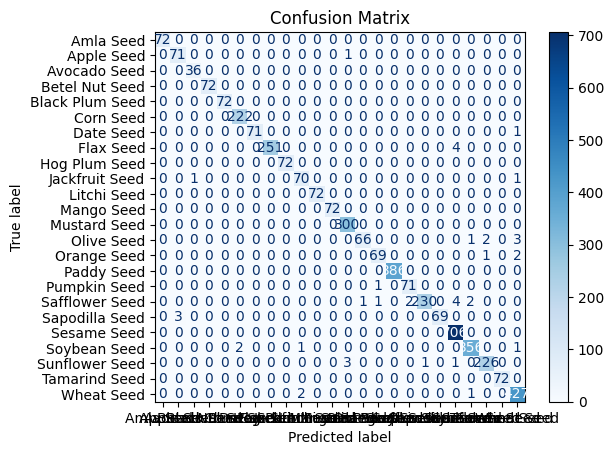

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=list(val_generator_eval.class_indices.keys())
)

disp.plot(cmap='Blues')
plt.title("Confusion Matrix")
plt.show()

In [26]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

class_names = [
    "Amla Seed",
    "Apple Seed",
    "Avocado Seed",
    "Betel Nut seed",
    "Black Plum Seed",
    "Corn Seed",
    "Date Seed",
    "Flax Seed",
    "Hog Plum Seed",
    "Jackfruit Seed",
    "Litchi Seed",
    "Mango Seed",
    "Mustard Seed",
    "Olive Seed",
    "Orange Seed",
    "Paddy Seed",
    "Pumpkin Seed",
    "Safflower Seed",
    "Sapodilla Seed",
    "Sesame Seed",
    "Soybean Seed",
    "Sunflower Seed",
    "Tamarind Seed",
    "Wheat Seed",
]

# Validation generator ko reset karo
val_generator.reset()

# Predictions
y_pred_probs = model.predict(val_generator, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)

# Actual labels
y_true = val_generator.classes

# Numerical confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(class_names))
)

print("\n===== NUMERICAL CONFUSION MATRIX =====")
print("Rows = Actual | Columns = Predicted\n")

print("Actual \\ Predicted")
print(cm)

print("\n===== CLASSIFICATION REPORT =====")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4
    )
)

131/131 ━━━━━━━━━━━━━━━━━━━━ 104s 792ms/step

===== NUMERICAL CONFUSION MATRIX =====
Rows = Actual | Columns = Predicted

Actual \ Predicted
[[  0   1   2   1   2   4   1   5   0   1   2   0   7   0   3   8   3   4
    0   9   8   5   0   6]
 [  0   2   0   1   1   0   1   4   0   2   0   5   3   1   1   7   0   3
    3  16   6   4   1  11]
 [  1   1   0   4   1   2   0   2   0   1   0   0   4   1   0   3   0   2
    0   4   3   2   1   4]
 [  1   0   1   2   1   2   5   7   1   0   2   0   2   2   0   7   2   6
    2  13   5   2   1   8]
 [  2   0   0   1   3   2   3   5   0   1   1   1   8   2   3   7   0   4
    0  13   6   3   1   6]
 [  1   7   2   4   4  16   7  12   5   6   6   4  17   5   1  25   5  18
    3  33  15   9   3  14]
 [  1   1   2   2   1   2   1   6   4   2   0   1   4   0   4   3   0   3
    0  15   5   2   3  10]
 [  3   2   3   3   5  18   1  15   2   6   8   4  19   6   2  29   4  16
    2  41  26  14   5  21]
 [  3   1   0   1   2   3   1   6   1   1   0   2  

In [17]:

from tensorflow.keras.models import load_model

model = load_model("seed_type4.2_mobilenetv2.h5")

print("Model loaded successfully")

Model loaded successfully


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step


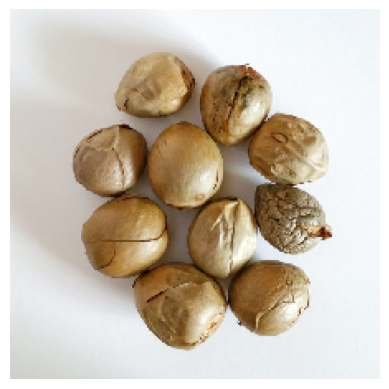

Prediction: Avocado Seed
Confidence: 99.82 %


In [32]:
import numpy as np
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt

img_path = r"C:\Users\dell\OneDrive\Desktop\Seed_Project\Seed_type4.2\Avocado Seed\original_051.jpg"



img = image.load_img(img_path, target_size=(224,224))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = img_array / 255.0

prediction = model.predict(img_array)

class_names = [
    "Amla Seed",
    "Apple Seed",
    "Avocado Seed",
    "Betel Nut seed",
    "Black Plum Seed",
    "Corn Seed",
    "Date Seed",
    "Flax Seed",
    "Hog Plum Seed",
    "Jackfruit Seed",
    "Litchi Seed",
    "Mango Seed",
    "Mustard Seed",
    "Olive Seed",
    "Orange Seed",
    "Paddy Seed",
    "Pumpkin Seed",
    "Safflower Seed",
    "Sapodilla Seed",
    "Sesame Seed",
    "Soybean Seed",
    "Sunflower Seed",
    "Tamarind Seed",
    "Wheat Seed",
]

predicted_class = class_names[np.argmax(prediction)]
confidence = np.max(prediction) * 100

plt.imshow(img)
plt.axis("off")
plt.show()

print("Prediction:", predicted_class)
print("Confidence:", round(confidence,2), "%")
